In [ ]:
# ============================================================
# CELL 1 - INSTALL DEPENDENCIES
# ============================================================

!pip -q install -U \
    transformers \
    accelerate \
    chromadb \
    sentence-transformers \
    langchain-text-splitters \
    timm \
    librosa \
    soundfile \
    gTTS \
    sacremoses \
    sentencepiece \
    scikit-learn \
    pandas \
    matplotlib \
    seaborn \
    jiwer \
    pydub

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 7.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 8.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 5.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1,000.0/1,000.0 kB 34.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 880.6/880.6 kB 63.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 880.6/880.6 kB 57.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 862.3/862.3 kB 59.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.8/883.8 kB 58.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━

In [ ]:
#!pip install -U --force-reinstall scikit-learn==1.5.2

In [ ]:
# ============================================================
# CELL 2 - IMPORTS
# ============================================================

import os
import re
import json
import math
import time
import random
import shutil
import zipfile
import warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from PIL import Image

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

import matplotlib.pyplot as plt
import seaborn as sns

import librosa
import soundfile as sf

from gtts import gTTS

import chromadb

from sentence_transformers import SentenceTransformer

from transformers import (
    AutoProcessor,
    AutoModel,
    AutoTokenizer,
    AutoModelForCausalLM,
    AutoModelForSpeechSeq2Seq,
    pipeline
)

from google.colab import files

warnings.filterwarnings("ignore")

print("Imports completed successfully.")

Imports completed successfully.


In [ ]:
# ============================================================
# CELL 3 - PROJECT CONFIGURATION
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# ------------------------------------------------------------
# MODEL NAMES
# ------------------------------------------------------------

SIGLIP_MODEL = "google/siglip-base-patch16-224"

BGE_MODEL = "BAAI/bge-small-en-v1.5"

QWEN_MODEL = "Qwen/Qwen2.5-0.5B-Instruct"

NLLB_MODEL = "facebook/nllb-200-distilled-600M"

WHISPER_MODEL = "openai/whisper-small"


# ------------------------------------------------------------
# RETRIEVAL SETTINGS
# ------------------------------------------------------------

RETRIEVAL_THRESHOLD = 0.40

TOP_K = 4

FALLBACK_TOP_K = 6

GROUNDING_THRESHOLD = 0.35

MAX_NEW_TOKENS = 256


# ------------------------------------------------------------
# TRAINING SETTINGS
# ------------------------------------------------------------

TRAIN_PER_CLASS = 150

VAL_PER_CLASS = 40

BATCH_SIZE = 32 # Added BATCH_SIZE

EPOCHS = 60

LEARNING_RATE = 1e-3

WEIGHT_DECAY = 1e-4


# ------------------------------------------------------------
# OUTPUT DIRECTORIES
# ------------------------------------------------------------

PROJECT_ROOT = Path("/content/AgricultureAssistant")

DATA_DIR = PROJECT_ROOT / "data"

OUTPUT_DIR = PROJECT_ROOT / "outputs"

MODEL_DIR = PROJECT_ROOT / "models"

CHROMA_DIR = PROJECT_ROOT / "chroma_db"

TEST_DIR = PROJECT_ROOT / "independent_test"

for folder in [
    PROJECT_ROOT,
    DATA_DIR,
    OUTPUT_DIR,
    MODEL_DIR,
    CHROMA_DIR,
    TEST_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)


print("Project directory:", PROJECT_ROOT)
print("Output directory:", OUTPUT_DIR)


Device: cuda
Project directory: /content/AgricultureAssistant
Output directory: /content/AgricultureAssistant/outputs


In [ ]:
# ============================================================
# CELL 4 - DISEASE LABELS
# ============================================================

DISEASE_LABELS = [
    "Apple Scab",
    "Apple Black Rot",
    "Apple Cedar Rust",

    "Cherry Powdery Mildew",

    "Corn Common Rust",
    "Corn Gray Leaf Spot",
    "Corn Northern Leaf Blight",

    "Grape Black Rot",
    "Grape Esca",
    "Grape Leaf Blight",

    "Peach Bacterial Spot",

    "Pepper Bacterial Spot",

    "Potato Early Blight",
    "Potato Late Blight",

    "Strawberry Leaf Scorch",

    "Tomato Bacterial Spot",
    "Tomato Early Blight",
    "Tomato Late Blight",

    "Healthy Plant"
]

print("Number of classes:", len(DISEASE_LABELS))

for i, label in enumerate(DISEASE_LABELS):
    print(i, "->", label)

Number of classes: 19
0 -> Apple Scab
1 -> Apple Black Rot
2 -> Apple Cedar Rust
3 -> Cherry Powdery Mildew
4 -> Corn Common Rust
5 -> Corn Gray Leaf Spot
6 -> Corn Northern Leaf Blight
7 -> Grape Black Rot
8 -> Grape Esca
9 -> Grape Leaf Blight
10 -> Peach Bacterial Spot
11 -> Pepper Bacterial Spot
12 -> Potato Early Blight
13 -> Potato Late Blight
14 -> Strawberry Leaf Scorch
15 -> Tomato Bacterial Spot
16 -> Tomato Early Blight
17 -> Tomato Late Blight
18 -> Healthy Plant


In [ ]:
# ============================================================
# CELL 5 - LOAD SIGLIP
# ============================================================

print("Loading SigLIP...")

siglip_processor = AutoProcessor.from_pretrained(
    SIGLIP_MODEL
)

siglip_backbone = AutoModel.from_pretrained(
    SIGLIP_MODEL
).to(device)

siglip_backbone.eval()

print("SigLIP loaded successfully.")

Loading SigLIP...


preprocessor_config.json:   0%|          | 0.00/368 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/432 [00:00<?, ?B/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


tokenizer_config.json:   0%|          | 0.00/711 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/2.40M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  813MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

SigLIP loaded successfully.


In [ ]:
# ============================================================
# SAFE SIGLIP IMAGE EMBEDDING FUNCTION
# ============================================================

@torch.no_grad()
def get_siglip_image_embedding(image):
    """
    Safely extracts a 2D image embedding from SigLIP.

    This handles different Transformers versions where
    get_image_features() may return:
      - Tensor
      - image_embeds
      - pooler_output
      - last_hidden_state
    """

    if isinstance(image, (str, Path)):
        image = Image.open(image).convert("RGB")

    inputs = siglip_processor(
        images=image,
        return_tensors="pt"
    )

    inputs = {
        k: v.to(device)
        for k, v in inputs.items()
    }

    output = siglip_backbone.get_image_features(**inputs)

    # --------------------------------------------------------
    # CASE 1: direct Tensor
    # --------------------------------------------------------

    if isinstance(output, torch.Tensor):
        feats = output

    # --------------------------------------------------------
    # CASE 2: model output object
    # --------------------------------------------------------

    else:

        feats = None

        # image_embeds
        if hasattr(output, "image_embeds"):

            candidate = output.image_embeds

            if candidate is not None:
                feats = candidate

        # pooler_output
        if feats is None and hasattr(output, "pooler_output"):

            candidate = output.pooler_output

            if candidate is not None:
                feats = candidate

        # last_hidden_state
        if feats is None and hasattr(output, "last_hidden_state"):

            candidate = output.last_hidden_state

            if candidate is not None:
                feats = candidate

        if feats is None:

            raise RuntimeError(
                "Could not extract image embedding from SigLIP output.\n"
                f"Output type: {type(output)}\n"
                f"Available attributes: {dir(output)}"
            )

    # --------------------------------------------------------
    # Make sure Tensor
    # --------------------------------------------------------

    if not isinstance(feats, torch.Tensor):

        raise TypeError(
            f"SigLIP embedding is not a Tensor. "
            f"Got {type(feats)}"
        )

    # --------------------------------------------------------
    # Remove sequence dimension if necessary
    # --------------------------------------------------------

    if feats.ndim == 3:

        # [batch, tokens, hidden]
        feats = feats[:, 0, :]

    elif feats.ndim == 4:

        # Defensive handling
        feats = feats.mean(dim=(2, 3))

    # --------------------------------------------------------
    # Expected shape = [batch, embedding_dim]
    # --------------------------------------------------------

    if feats.ndim != 2:

        raise RuntimeError(
            f"Unexpected SigLIP embedding shape: {feats.shape}"
        )

    # --------------------------------------------------------
    # L2 normalization
    # --------------------------------------------------------

    feats = F.normalize(
        feats.float(),
        p=2,
        dim=-1
    )

    return feats


print("Safe SigLIP embedding function created.")

Safe SigLIP embedding function created.


In [ ]:
# ============================================================
# CELL 6 - DOWNLOAD PLANTVILLAGE
# ============================================================

PLANTVILLAGE_DIR = DATA_DIR / "PlantVillage"

if not PLANTVILLAGE_DIR.exists():

    print("Downloading PlantVillage dataset...")

    !git clone --depth 1 https://github.com/spMohanty/PlantVillage-Dataset.git /content/AgricultureAssistant/data/PlantVillage

else:

    print("PlantVillage directory already exists.")

Cloning into '/content/AgricultureAssistant/data/PlantVillage'...
remote: Enumerating objects: 163219, done.
remote: Counting objects: 100% (163219/163219), done.
remote: Compressing objects: 100% (163125/163125), done.
remote: Total 163219 (delta 93), reused 163215 (delta 93), pack-reused 0 (from 0)
Receiving objects: 100% (163219/163219), 2.00 GiB | 25.98 MiB/s, done.
Resolving deltas: 100% (93/93), done.
Checking connectivity: 163219, done.
Updating files: 100% (182404/182404), done.


In [ ]:
# ============================================================
# CELL 7 - PLANTVILLAGE FOLDER MAPPING
# ============================================================

PV_FOLDER_TO_LABEL = {

    "Apple___Apple_scab":
        "Apple Scab",

    "Apple___Black_rot":
        "Apple Black Rot",

    "Apple___Cedar_apple_rust":
        "Apple Cedar Rust",

    "Cherry_(including_sour)___Powdery_mildew":
        "Cherry Powdery Mildew",

    "Corn_(maize)___Common_rust_":
        "Corn Common Rust",

    "Corn_(maize)___Cercospora_leaf_spot:Gray_leaf_spot":
        "Corn Gray Leaf Spot",

    "Corn_(maize)___Northern_Leaf_Blight":
        "Corn Northern Leaf Blight",

    "Grape___Black_rot":
        "Grape Black Rot",

    "Grape___Esca_(Black_Measles)":
        "Grape Esca",

    "Grape___Leaf_blight_(Isariopsis_Leaf_Spot)":
        "Grape Leaf Blight",

    "Peach___Bacterial_spot":
        "Peach Bacterial Spot",

    "Pepper,_bell___Bacterial_spot":
        "Pepper Bacterial Spot",

    "Potato___Early_blight":
        "Potato Early Blight",

    "Potato___Late_blight":
        "Potato Late Blight",

    "Strawberry___Leaf_scorch":
        "Strawberry Leaf Scorch",

    "Tomato___Bacterial_spot":
        "Tomato Bacterial Spot",

    "Tomato___Early_blight":
        "Tomato Early Blight",

    "Tomato___Late_blight":
        "Tomato Late Blight",

    "Tomato___healthy":
        "Healthy Plant"
}


LABEL_TO_FOLDERS = defaultdict(list)

for folder, label in PV_FOLDER_TO_LABEL.items():

    LABEL_TO_FOLDERS[label].append(folder)


print("Dataset mapping created.")

for label in DISEASE_LABELS:

    print(
        label,
        "->",
        LABEL_TO_FOLDERS.get(label, [])
    )

Dataset mapping created.
Apple Scab -> ['Apple___Apple_scab']
Apple Black Rot -> ['Apple___Black_rot']
Apple Cedar Rust -> ['Apple___Cedar_apple_rust']
Cherry Powdery Mildew -> ['Cherry_(including_sour)___Powdery_mildew']
Corn Common Rust -> ['Corn_(maize)___Common_rust_']
Corn Gray Leaf Spot -> ['Corn_(maize)___Cercospora_leaf_spot:Gray_leaf_spot']
Corn Northern Leaf Blight -> ['Corn_(maize)___Northern_Leaf_Blight']
Grape Black Rot -> ['Grape___Black_rot']
Grape Esca -> ['Grape___Esca_(Black_Measles)']
Grape Leaf Blight -> ['Grape___Leaf_blight_(Isariopsis_Leaf_Spot)']
Peach Bacterial Spot -> ['Peach___Bacterial_spot']
Pepper Bacterial Spot -> ['Pepper,_bell___Bacterial_spot']
Potato Early Blight -> ['Potato___Early_blight']
Potato Late Blight -> ['Potato___Late_blight']
Strawberry Leaf Scorch -> ['Strawberry___Leaf_scorch']
Tomato Bacterial Spot -> ['Tomato___Bacterial_spot']
Tomato Early Blight -> ['Tomato___Early_blight']
Tomato Late Blight -> ['Tomato___Late_blight']
Healthy Plant

In [ ]:
# ============================================================
# CELL 8 — PLANTVILLAGE DATASET + ROBUST FOLDER DISCOVERY
# ============================================================

import os
import glob
import random
import re
import json
import shutil
from pathlib import Path

import torch
import numpy as np
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# ------------------------------------------------------------
# 1. BASIC CONFIGURATION
# ------------------------------------------------------------

PV_DIR = "/content/PlantVillage-Dataset"

# Your project dataset directory
PROJECT_DATA_DIR = os.path.join(PROJECT_ROOT, "data", "PlantVillage")

# Expected color-image directory
COLOR_DIR = os.path.join(PV_DIR, "raw", "color")

print("=" * 70)
print("PLANTVILLAGE DATASET SETUP")
print("=" * 70)

print("PlantVillage root:", PV_DIR)
print("Expected color folder:", COLOR_DIR)


# ------------------------------------------------------------
# 2. DOWNLOAD DATASET IF IT DOES NOT EXIST
# ------------------------------------------------------------

if not os.path.isdir(PV_DIR):

    print("\nPlantVillage dataset not found.")
    print("Downloading dataset...")

    !git clone --depth 1 https://github.com/spMohanty/PlantVillage-Dataset.git /content/PlantVillage-Dataset

else:

    print("\nPlantVillage dataset already exists.")
    print("Skipping download.")


# ------------------------------------------------------------
# 3. FIND THE ACTUAL COLOR DIRECTORY
# ------------------------------------------------------------

possible_color_dirs = [
    "/content/PlantVillage-Dataset/raw/color",
    "/content/PlantVillage-Dataset/plantvillage dataset/color",
    "/content/PlantVillage-Dataset/color",
]

found_color_dir = None

for candidate in possible_color_dirs:

    if os.path.isdir(candidate):

        # Check whether it actually contains class folders
        subdirs = [
            d for d in os.listdir(candidate)
            if os.path.isdir(os.path.join(candidate, d))
        ]

        if len(subdirs) > 0:
            found_color_dir = candidate
            break


# If standard locations are not found, search recursively
if found_color_dir is None:

    print("\nStandard color directory not found.")
    print("Searching recursively...")

    candidate_dirs = []

    for root, dirs, files in os.walk(PV_DIR):

        class_like_dirs = [
            d for d in dirs
            if "___" in d
        ]

        if len(class_like_dirs) >= 3:
            candidate_dirs.append(root)

    if candidate_dirs:
        found_color_dir = candidate_dirs[0]


if found_color_dir is None:

    raise FileNotFoundError(
        "Could not locate PlantVillage color-image directory.\n"
        "Please check whether the PlantVillage dataset was downloaded correctly."
    )


COLOR_DIR = found_color_dir

print("\nActual dataset directory:")
print(COLOR_DIR)


# ------------------------------------------------------------
# 4. LIST ALL AVAILABLE PLANTVILLAGE FOLDERS
# ------------------------------------------------------------

available_folders = []

for item in sorted(os.listdir(COLOR_DIR)):

    full_path = os.path.join(COLOR_DIR, item)

    if os.path.isdir(full_path):
        available_folders.append(item)


print("\nNumber of class folders found:", len(available_folders))

print("\nAvailable PlantVillage folders:")
for folder in available_folders:
    print("  ", folder)


# ------------------------------------------------------------
# 5. NORMALIZE FOLDER NAMES
# ------------------------------------------------------------
# This is the important fix.
#
# Different versions / downloads may contain:
#
# Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
#
# Corn_(maize)___Cercospora_leaf_spot:Gray_leaf_spot
#
# Corn\_(maize)\/___...
#
# etc.
#
# We normalize them before matching.


def normalize_folder_name(name):

    name = str(name)

    # Remove escape characters
    name = name.replace("\\", "")

    # Replace different separators
    name = name.replace(":", " ")
    name = name.replace("-", " ")
    name = name.replace("_", " ")

    # Remove brackets
    name = name.replace("(", " ")
    name = name.replace(")", " ")

    # Lowercase
    name = name.lower()

    # Keep only letters/numbers/spaces
    name = re.sub(r"[^a-z0-9\s]", " ", name)

    # Remove repeated spaces
    name = re.sub(r"\s+", " ", name).strip()

    return name


normalized_available = {
    folder: normalize_folder_name(folder)
    for folder in available_folders
}


# ------------------------------------------------------------
# 6. PROJECT LABEL → SEARCH TERMS
# ------------------------------------------------------------
# Instead of exact folder names, use keywords.
# This avoids the previous Corn Gray Leaf Spot error.


FOLDER_SEARCH_RULES = {

    "Apple Scab": [
        ["apple", "scab"]
    ],

    "Apple Black Rot": [
        ["apple", "black", "rot"]
    ],

    "Apple Cedar Rust": [
        ["apple", "cedar", "rust"]
    ],

    "Cherry Powdery Mildew": [
        ["cherry", "powdery", "mildew"]
    ],

    "Corn Common Rust": [
        ["corn", "maize", "common", "rust"],
        ["corn", "common", "rust"]
    ],

    "Corn Gray Leaf Spot": [
        ["corn", "maize", "cercospora", "leaf", "spot"],
        ["corn", "gray", "leaf", "spot"],
        ["corn", "maize", "gray", "leaf", "spot"]
    ],

    "Corn Northern Leaf Blight": [
        ["corn", "maize", "northern", "leaf", "blight"],
        ["corn", "northern", "leaf", "blight"]
    ],

    "Grape Black Rot": [
        ["grape", "black", "rot"]
    ],

    "Grape Esca": [
        ["grape", "esca", "black", "measles"]
    ],

    "Grape Esca Black Measles": [
        ["grape", "esca", "black", "measles"]
    ],

    "Grape Leaf Blight": [
        ["grape", "leaf", "blight"],
        ["grape", "isariopsis", "leaf", "spot"]
    ],

    "Peach Bacterial Spot": [
        ["peach", "bacterial", "spot"]
    ],

    "Pepper Bacterial Spot": [
        ["pepper", "bell", "bacterial", "spot"],
        ["pepper", "bacterial", "spot"]
    ],

    "Strawberry Leaf Scorch": [
        ["strawberry", "leaf", "scorch"]
    ],

    "Potato Early Blight": [
        ["potato", "early", "blight"]
    ],

    "Potato Late Blight": [
        ["potato", "late", "blight"]
    ],

    "Tomato Bacterial Spot": [
        ["tomato", "bacterial", "spot"]
    ],

    "Tomato Early Blight": [
        ["tomato", "early", "blight"]
    ],

    "Tomato Late Blight": [
        ["tomato", "late", "blight"]
    ],

    "Healthy Plant": [
        ["healthy"]
    ]
}


# ------------------------------------------------------------
# 7. FIND MATCHING SOURCE FOLDERS
# ------------------------------------------------------------

def find_matching_folders(label):

    rules = FOLDER_SEARCH_RULES.get(label, [])

    matches = []

    for original_folder, normalized_folder in normalized_available.items():

        for keywords in rules:

            if all(keyword in normalized_folder for keyword in keywords):

                matches.append(original_folder)
                break

    return sorted(set(matches))


# ------------------------------------------------------------
# 8. BUILD LABEL → ACTUAL FOLDER MAPPING
# ------------------------------------------------------------

LABEL_TO_FOLDERS = {}

print("\n")
print("=" * 70)
print("DATASET LABEL MATCHING")
print("=" * 70)

for label in DISEASE_LABELS:

    matches = find_matching_folders(label)

    LABEL_TO_FOLDERS[label] = matches

    print(f"\n{label}")

    if matches:

        for folder in matches:
            print("   ✓", folder)

    else:

        print("   ✗ NO MATCH FOUND")


# ------------------------------------------------------------
# 9. IMPORTANT VALIDATION
# ------------------------------------------------------------

missing_labels = [
    label
    for label, folders in LABEL_TO_FOLDERS.items()
    if len(folders) == 0
]

if missing_labels:

    print("\n")
    print("=" * 70)
    print("WARNING — SOME LABELS HAVE NO DATASET FOLDER")
    print("=" * 70)

    for label in missing_labels:
        print("  ✗", label)

    print("\nThe training code will stop instead of silently training")
    print("with missing classes.")

    raise FileNotFoundError(
        "Missing PlantVillage folders for: "
        + ", ".join(missing_labels)
    )


print("\n")
print("=" * 70)
print("ALL 19 PROJECT CLASSES FOUND")
print("=" * 70)


# ------------------------------------------------------------
# 10. REVERSE MAPPING
# ------------------------------------------------------------

PV_FOLDER_TO_LABEL = {}

for label, folders in LABEL_TO_FOLDERS.items():

    for folder in folders:

        PV_FOLDER_TO_LABEL[folder] = label


# ------------------------------------------------------------
# 11. SAVE DATASET MAPPING
# ------------------------------------------------------------

mapping_file = os.path.join(
    MODEL_DIR,
    "plantvillage_folder_mapping.json"
)

with open(mapping_file, "w", encoding="utf-8") as f:

    json.dump(
        {
            "color_dir": COLOR_DIR,
            "label_to_folders": LABEL_TO_FOLDERS,
            "folder_to_label": PV_FOLDER_TO_LABEL
        },
        f,
        indent=2,
        ensure_ascii=False
    )

print("\nDataset mapping saved to:")
print(mapping_file)


# ------------------------------------------------------------
# 12. COLLECT TRAINING + VALIDATION FILES
# ------------------------------------------------------------

random.seed(SEED)

def collect_split_paths(
    per_class_train,
    per_class_val,
    seed=42
):

    rng = random.Random(seed)

    train_items = []
    val_items = []

    print("\n")
    print("=" * 70)
    print("COLLECTING TRAINING / VALIDATION IMAGES")
    print("=" * 70)

    for label in DISEASE_LABELS:

        source_folders = LABEL_TO_FOLDERS.get(label, [])

        if not source_folders:

            raise FileNotFoundError(
                f"No dataset folder found for class: {label}"
            )

        all_class_images = []

        # ----------------------------------------------------
        # Collect images from every matching folder
        # ----------------------------------------------------

        for folder in source_folders:

            folder_path = os.path.join(
                COLOR_DIR,
                folder
            )

            if not os.path.isdir(folder_path):

                print(
                    f"WARNING: folder disappeared: {folder_path}"
                )

                continue

            image_files = []

            for filename in os.listdir(folder_path):

                if filename.lower().endswith(
                    (".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG")
                ):

                    image_files.append(
                        os.path.join(
                            folder_path,
                            filename
                        )
                    )

            all_class_images.extend(image_files)

        # ----------------------------------------------------
        # Check class
        # ----------------------------------------------------

        if len(all_class_images) == 0:

            raise FileNotFoundError(
                f"No images found for class: {label}"
            )

        # Shuffle
        rng.shuffle(all_class_images)

        # ----------------------------------------------------
        # Take requested amount
        # ----------------------------------------------------

        total_required = per_class_train + per_class_val

        if len(all_class_images) < total_required:

            print(
                f"WARNING: {label} has only "
                f"{len(all_class_images)} images. "
                f"Requested {total_required}."
            )

        actual_train_count = min(
            per_class_train,
            len(all_class_images)
        )

        train_images = all_class_images[
            :actual_train_count
        ]

        remaining_images = all_class_images[
            actual_train_count:
        ]

        actual_val_count = min(
            per_class_val,
            len(remaining_images)
        )

        val_images = remaining_images[
            :actual_val_count
        ]

        train_items.extend(
            [
                (path, label)
                for path in train_images
            ]
        )

        val_items.extend(
            [
                (path, label)
                for path in val_images
            ]
        )

        print(
            f"{label:35s} "
            f"Train={len(train_images):3d} "
            f"Val={len(val_images):3d}"
        )

    # Final shuffle
    rng.shuffle(train_items)
    rng.shuffle(val_items)

    return train_items, val_items


# ------------------------------------------------------------
# 13. CREATE TRAIN / VALIDATION SPLIT
# ------------------------------------------------------------

train_items, val_items = collect_split_paths(
    per_class_train=TRAIN_PER_CLASS,
    per_class_val=VAL_PER_CLASS,
    seed=SEED
)


print("\n")
print("=" * 70)
print("DATASET SPLIT COMPLETE")
print("=" * 70)

print("Training images   :", len(train_items))
print("Validation images :", len(val_items))


# ------------------------------------------------------------
# 14. VERIFY ALL LABELS ARE PRESENT
# ------------------------------------------------------------

train_labels_present = set(
    label
    for _, label in train_items
)

val_labels_present = set(
    label
    for _, label in val_items
)

missing_train = set(DISEASE_LABELS) - train_labels_present
missing_val = set(DISEASE_LABELS) - val_labels_present

if missing_train:

    raise RuntimeError(
        "Training split is missing classes: "
        + ", ".join(sorted(missing_train))
    )

if missing_val:

    raise RuntimeError(
        "Validation split is missing classes: "
        + ", ".join(sorted(missing_val))
    )


print("\n✓ All 19 classes are present in training.")
print("✓ All 19 classes are present in validation.")


# ------------------------------------------------------------
# 15. ROBUST SIGLIP IMAGE EMBEDDING FUNCTION
# ------------------------------------------------------------
# IMPORTANT:
# Some Transformers versions return:
#
# BaseModelOutputWithPooling
#
# instead of a Tensor.
#
# Therefore we must NOT directly do:
#
# feats = model.get_image_features(...)
# feats.norm(...)
#
# We first extract the actual tensor.


@torch.no_grad()
def get_siglip_image_embedding(inputs):

    output = siglip_backbone.get_image_features(
        **inputs
    )

    # Case 1: already a Tensor
    if isinstance(output, torch.Tensor):

        feats = output

    # Case 2: model output with image_embeds
    elif hasattr(output, "image_embeds") and \
         output.image_embeds is not None:

        feats = output.image_embeds

    # Case 3: model output with pooler_output
    elif hasattr(output, "pooler_output") and \
         output.pooler_output is not None:

        feats = output.pooler_output

    # Case 4: model output with last_hidden_state
    elif hasattr(output, "last_hidden_state") and \
         output.last_hidden_state is not None:

        feats = output.last_hidden_state

        # [batch, sequence, hidden]
        if feats.ndim == 3:

            feats = feats[:, 0, :]

    else:

        raise TypeError(
            "Could not extract a Tensor from SigLIP output.\n"
            f"Output type: {type(output)}"
        )

    # --------------------------------------------------------
    # Make sure dimensions are correct
    # --------------------------------------------------------

    if feats.ndim == 3:

        feats = feats[:, 0, :]

    if feats.ndim != 2:

        raise ValueError(
            f"Expected SigLIP embeddings with shape "
            f"[batch, hidden], got {tuple(feats.shape)}"
        )

    # --------------------------------------------------------
    # L2 normalization
    # --------------------------------------------------------

    feats = feats.float()

    feats = feats / feats.norm(
        dim=-1,
        keepdim=True
    ).clamp_min(1e-12)

    return feats


# ------------------------------------------------------------
# 16. EXTRACT SIGLIP EMBEDDINGS
# ------------------------------------------------------------

@torch.no_grad()
def extract_embeddings(
    items,
    batch_size=BATCH_SIZE
):

    embeddings = []
    labels = []

    label_to_idx = {
        label: idx
        for idx, label in enumerate(DISEASE_LABELS)
    }

    total = len(items)

    print("\nExtracting SigLIP embeddings...")
    print("Total images:", total)

    for start in range(
        0,
        total,
        batch_size
    ):

        batch = items[
            start:start + batch_size
        ]

        images = []
        valid_labels = []

        for path, label in batch:

            try:

                image = Image.open(path).convert("RGB")

                images.append(image)
                valid_labels.append(label)

            except Exception as e:

                print(
                    f"Skipping corrupted image: {path}"
                )

                print("Reason:", e)

        if not images:
            continue

        # ----------------------------------------------------
        # Processor
        # ----------------------------------------------------

        inputs = siglip_processor(
            images=images,
            return_tensors="pt"
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        # ----------------------------------------------------
        # ROBUST SigLIP embedding
        # ----------------------------------------------------

        feats = get_siglip_image_embedding(
            inputs
        )

        embeddings.append(
            feats.cpu()
        )

        labels.extend(
            [
                label_to_idx[label]
                for label in valid_labels
            ]
        )

        # Progress
        processed = min(
            start + batch_size,
            total
        )

        print(
            f"\rProcessed "
            f"{processed}/{total}",
            end=""
        )

    print()

    if not embeddings:

        raise RuntimeError(
            "No embeddings were extracted."
        )

    X = torch.cat(
        embeddings,
        dim=0
    )

    y = torch.tensor(
        labels,
        dtype=torch.long
    )

    return X, y


# ------------------------------------------------------------
# 17. EXTRACT TRAINING FEATURES
# ------------------------------------------------------------

X_train, y_train = extract_embeddings(
    train_items,
    batch_size=BATCH_SIZE
)

print(
    "\nTraining feature matrix:",
    tuple(X_train.shape)
)

print(
    "Training labels:",
    tuple(y_train.shape)
)


# ------------------------------------------------------------
# 18. EXTRACT VALIDATION FEATURES
# ------------------------------------------------------------

X_val, y_val = extract_embeddings(
    val_items,
    batch_size=BATCH_SIZE
)

print(
    "\nValidation feature matrix:",
    tuple(X_val.shape)
)

print(
    "Validation labels:",
    tuple(y_val.shape)
)


# ------------------------------------------------------------
# 19. TRAIN LINEAR CLASSIFIER
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("TRAINING LINEAR CLASSIFIER")
print("=" * 70)

X_train_np = X_train.numpy()
y_train_np = y_train.numpy()

X_val_np = X_val.numpy()
y_val_np = y_val.numpy()


classifier = LogisticRegression(
    max_iter=2000,
    random_state=SEED
    # multi_class="auto" # Removed the problematic argument
)

classifier.fit(
    X_train_np,
    y_train_np
)


# ------------------------------------------------------------
# 20. VALIDATION PREDICTION
# ------------------------------------------------------------

val_predictions = classifier.predict(
    X_val_np
)

val_accuracy = accuracy_score(
    y_val_np,
    val_predictions
)

print(
    f"\nValidation Accuracy: "
    f"{val_accuracy * 100:.2f}%"
)


# ------------------------------------------------------------
# 21. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nClassification Report:\n")

print(
    classification_report(
        y_val_np,
        val_predictions,
        labels=list(range(len(DISEASE_LABELS))),
        target_names=DISEASE_LABELS,
        zero_division=0
    )
)


# ------------------------------------------------------------
# 22. SAVE CLASSIFIER
# ------------------------------------------------------------

classifier_path = os.path.join(
    MODEL_DIR,
    "siglip_linear_classifier.pkl"
)

import joblib

joblib.dump(
    classifier,
    classifier_path
)

print("\nClassifier saved:")
print(classifier_path)


# ------------------------------------------------------------
# 23. SAVE TRAINING METADATA
# ------------------------------------------------------------

training_metadata = {

    "model": SIGLIP_MODEL,

    "classifier": "LogisticRegression",

    "classes": DISEASE_LABELS,

    "num_classes": len(DISEASE_LABELS),

    "seed": SEED,

    "train_per_class": TRAIN_PER_CLASS,

    "validation_per_class": VAL_PER_CLASS,

    "total_training_images": len(train_items),

    "total_validation_images": len(val_items),

    "feature_dimension": int(X_train.shape[1]),

    "validation_accuracy": float(val_accuracy),

    "dataset_directory": COLOR_DIR,

    "folder_mapping": LABEL_TO_FOLDERS
}


metadata_path = os.path.join(
    MODEL_DIR,
    "training_metadata.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        training_metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


print("\nTraining metadata saved:")
print(metadata_path)


# ------------------------------------------------------------
# 24. FINAL SUMMARY
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("CELL 8 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Dataset directory :", COLOR_DIR)
print("Classes            :", len(DISEASE_LABELS))
print("Training images    :", len(train_items))
print("Validation images  :", len(val_items))
print("Feature dimension  :", X_train.shape[1])
print(
    "Validation accuracy:",
    f"{val_accuracy * 100:.2f}%"
)

print("\n✓ PlantVillage folders matched automatically")
print("✓ Corn Gray Leaf Spot issue fixed")
print("✓ SigLIP output compatibility fixed")
print("✓ Embeddings extracted")
print("✓ Classifier trained")
print("✓ Classifier saved")
print("✓ Metadata saved")

PLANTVILLAGE DATASET SETUP
PlantVillage root: /content/PlantVillage-Dataset
Expected color folder: /content/PlantVillage-Dataset/raw/color

PlantVillage dataset not found.
Cloning into '/content/PlantVillage-Dataset'...
remote: Enumerating objects: 163219, done.
remote: Counting objects: 100% (163219/163219), done.
remote: Compressing objects: 100% (163125/163125), done.
remote: Total 163219 (delta 93), reused 163215 (delta 93), pack-reused 0 (from 0)
Receiving objects: 100% (163219/163219), 2.00 GiB | 24.47 MiB/s, done.
Resolving deltas: 100% (93/93), done.
Updating files: 100% (182404/182404), done.

Actual dataset directory:
/content/PlantVillage-Dataset/raw/color

Number of class folders found: 38

Available PlantVillage folders:
   Apple___Apple_scab
   Apple___Black_rot
   Apple___Cedar_apple_rust
   Apple___healthy
   Blueberry___healthy
   Cherry_(including_sour)___Powdery_mildew
   Cherry_(including_sour)___healthy
   Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
   Corn_

In [ ]:
# ============================================================
# CELL 9 - VISION PREDICTION / VISION AGENT
# ============================================================

import os
import joblib
import numpy as np
import torch
from PIL import Image

print("=" * 70)
print("CELL 9 - VISION PREDICTION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load trained classifier
# ------------------------------------------------------------

classifier_path = MODEL_DIR / "siglip_linear_classifier.pkl"

classifier = joblib.load(classifier_path)

print("✓ Classifier loaded")
print("✓ Classifier type:", type(classifier).__name__)

# ------------------------------------------------------------
# 2. Restore class information if missing
# ------------------------------------------------------------

if not hasattr(classifier, "classes_"):

    if not hasattr(classifier, "coef_"):
        raise RuntimeError(
            "The saved classifier is not trained correctly. "
            "Please rerun Cell 8."
        )

    number_of_classes = classifier.coef_.shape[0]

    if number_of_classes != len(DISEASE_LABELS):
        raise RuntimeError(
            f"Classifier has {number_of_classes} classes, "
            f"but DISEASE_LABELS contains {len(DISEASE_LABELS)} classes."
        )

    classifier.classes_ = np.arange(number_of_classes)

    print("✓ Class information restored")

else:
    print("✓ Class information already available")

print("✓ Number of classes:", len(classifier.classes_))

# ------------------------------------------------------------
# 3. Prediction function
# ------------------------------------------------------------

def predict_disease(image_path, top_k=5):

    if not os.path.exists(image_path):
        raise FileNotFoundError(
            f"Image not found: {image_path}"
        )

    image = Image.open(image_path).convert("RGB")

    inputs = siglip_processor(
        images=image,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        features = get_siglip_image_embedding(inputs)

    features_np = features.cpu().numpy()

    probabilities = classifier.predict_proba(features_np)[0]

    sorted_indices = np.argsort(probabilities)[::-1]

    top_index = sorted_indices[0]

    predicted_class_index = int(
        classifier.classes_[top_index]
    )

    predicted_label = DISEASE_LABELS[
        predicted_class_index
    ]

    confidence = float(
        probabilities[top_index]
    )

    top_predictions = []

    for index in sorted_indices[:top_k]:

        class_index = int(
            classifier.classes_[index]
        )

        top_predictions.append({
            "label": DISEASE_LABELS[class_index],
            "confidence": float(probabilities[index])
        })

    return {
        "predicted_label": predicted_label,
        "confidence": confidence,
        "top_predictions": top_predictions
    }


print("\n✓ Prediction function created successfully")
print("✓ CELL 9 COMPLETED SUCCESSFULLY")

CELL 9 - VISION PREDICTION
✓ Classifier loaded
✓ Classifier type: LogisticRegression
✓ Class information already available
✓ Number of classes: 19

✓ Prediction function created successfully
✓ CELL 9 COMPLETED SUCCESSFULLY


In [ ]:
# ============================================================
# CELL 10 - AGRICULTURAL KNOWLEDGE BASE
# ============================================================

print("=" * 70)
print("CELL 10 - AGRICULTURAL KNOWLEDGE BASE")
print("=" * 70)

knowledge_base = {

    "Apple Scab": {
        "symptoms": "Olive green to brown spots on leaves and fruit.",
        "cause": "Fungal disease caused by Venturia inaequalis.",
        "treatment": "Remove infected leaves and fruit. Improve air circulation. Use recommended fungicide according to agricultural guidance.",
        "prevention": "Maintain orchard sanitation and avoid prolonged leaf wetness."
    },

    "Apple Black Rot": {
        "symptoms": "Brown circular leaf spots and dark lesions on fruit.",
        "cause": "Fungal disease caused by Botryosphaeria obtusa.",
        "treatment": "Remove infected plant material and maintain orchard sanitation.",
        "prevention": "Prune infected branches and remove diseased fruit."
    },

    "Apple Cedar Rust": {
        "symptoms": "Yellow-orange spots on apple leaves.",
        "cause": "Fungal disease caused by Gymnosporangium species.",
        "treatment": "Remove infected material and use recommended fungicide when appropriate.",
        "prevention": "Maintain good orchard sanitation."
    },

    "Cherry Powdery Mildew": {
        "symptoms": "White powdery growth on leaves and young shoots.",
        "cause": "Fungal disease.",
        "treatment": "Remove severely infected leaves and improve air circulation.",
        "prevention": "Avoid excessive humidity and overcrowding."
    },

    "Corn Common Rust": {
        "symptoms": "Small reddish-brown rust-colored pustules on leaves.",
        "cause": "Fungal disease caused by Puccinia species.",
        "treatment": "Monitor disease development and use recommended fungicide when necessary.",
        "prevention": "Use resistant varieties and maintain proper crop management."
    },

    "Corn Gray Leaf Spot": {
        "symptoms": "Long rectangular gray or brown lesions on leaves.",
        "cause": "Fungal disease caused by Cercospora species.",
        "treatment": "Remove heavily infected plant material and follow recommended disease management.",
        "prevention": "Use resistant varieties and maintain field sanitation."
    },

    "Corn Northern Leaf Blight": {
        "symptoms": "Long gray-green cigar-shaped lesions on leaves.",
        "cause": "Fungal disease caused by Exserohilum turcicum.",
        "treatment": "Monitor crop and apply recommended fungicide when required.",
        "prevention": "Use resistant varieties and crop rotation."
    },

    "Peach Bacterial Spot": {
        "symptoms": "Small dark spots on leaves and fruit.",
        "cause": "Bacterial disease.",
        "treatment": "Remove infected plant material and follow recommended bacterial disease management.",
        "prevention": "Maintain orchard sanitation and avoid unnecessary leaf wetness."
    },

    "Grape Black Rot": {
        "symptoms": "Brown circular lesions on leaves and dark shriveled fruit.",
        "cause": "Fungal disease caused by Guignardia bidwellii.",
        "treatment": "Remove infected berries and leaves and follow recommended fungicide practices.",
        "prevention": "Maintain vineyard sanitation."
    },

    "Grape Esca": {
        "symptoms": "Leaf discoloration and internal wood damage.",
        "cause": "Fungal disease complex.",
        "treatment": "Remove severely affected plant material and monitor vines.",
        "prevention": "Use healthy planting material and maintain vineyard hygiene."
    },

    "Grape Leaf Blight": {
        "symptoms": "Brown or dark lesions on grape leaves.",
        "cause": "Fungal disease.",
        "treatment": "Remove infected leaves and follow recommended disease management.",
        "prevention": "Improve air circulation and vineyard sanitation."
    },

    "Pepper Bacterial Spot": {
        "symptoms": "Small dark spots on leaves and fruit.",
        "cause": "Bacterial disease caused by Xanthomonas species.",
        "treatment": "Remove infected plant material and use recommended bacterial disease control.",
        "prevention": "Use disease-free seeds and avoid overhead irrigation."
    },

    "Strawberry Leaf Scorch": {
        "symptoms": "Dark purple or brown spots on strawberry leaves.",
        "cause": "Fungal disease.",
        "treatment": "Remove infected leaves and maintain good field sanitation.",
        "prevention": "Improve air circulation and avoid excessive moisture."
    },

    "Potato Early Blight": {
        "symptoms": "Dark circular lesions with concentric rings on older leaves.",
        "cause": "Fungal disease caused by Alternaria species.",
        "treatment": "Remove infected plant material and follow recommended fungicide practices.",
        "prevention": "Use crop rotation and maintain proper field sanitation."
    },

    "Potato Late Blight": {
        "symptoms": "Dark water-soaked lesions on leaves and stems.",
        "cause": "Disease caused by Phytophthora infestans.",
        "treatment": "Remove severely infected material and follow recommended late-blight management.",
        "prevention": "Avoid prolonged leaf wetness and use resistant varieties when available."
    },

    "Tomato Bacterial Spot": {
        "symptoms": "Small dark spots on tomato leaves and fruit.",
        "cause": "Bacterial disease caused by Xanthomonas species.",
        "treatment": "Remove infected plant material and follow recommended bacterial disease management.",
        "prevention": "Use disease-free seeds and avoid overhead irrigation."
    },

    "Tomato Early Blight": {
        "symptoms": "Brown circular lesions with concentric rings on leaves.",
        "cause": "Fungal disease caused by Alternaria species.",
        "treatment": "Remove infected leaves and use recommended fungicide when appropriate.",
        "prevention": "Maintain field sanitation and use crop rotation."
    },

    "Tomato Late Blight": {
        "symptoms": "Large dark water-soaked lesions on leaves and stems.",
        "cause": "Disease caused by Phytophthora infestans.",
        "treatment": "Remove severely infected material and follow recommended disease management.",
        "prevention": "Reduce leaf wetness and improve air circulation."
    },

    "Healthy Plant": {
        "symptoms": "No visible major disease symptoms.",
        "cause": "No major disease detected.",
        "treatment": "Continue normal crop care and monitoring.",
        "prevention": "Maintain proper irrigation, nutrition, sanitation, and regular monitoring."
    }
}

# ------------------------------------------------------------
# Verify knowledge base
# ------------------------------------------------------------

print("✓ Knowledge base created")
print("✓ Number of entries:", len(knowledge_base))

missing_classes = [
    label for label in DISEASE_LABELS
    if label not in knowledge_base
]

if missing_classes:
    raise ValueError(
        f"Missing knowledge-base entries: {missing_classes}"
    )

print("✓ All 19 disease classes are covered")
print("✓ CELL 10 COMPLETED SUCCESSFULLY")

CELL 10 - AGRICULTURAL KNOWLEDGE BASE
✓ Knowledge base created
✓ Number of entries: 19
✓ All 19 disease classes are covered
✓ CELL 10 COMPLETED SUCCESSFULLY


In [ ]:
# ============================================================
# CELL 11 - BGE EMBEDDINGS + CHROMADB
# ============================================================

print("=" * 70)
print("CELL 11 - BGE EMBEDDINGS + CHROMADB")
print("=" * 70)

from sentence_transformers import SentenceTransformer
import chromadb

# ------------------------------------------------------------
# 1. Load BGE model
# ------------------------------------------------------------

BGE_MODEL_NAME = "BAAI/bge-small-en-v1.5"

bge_model = SentenceTransformer(BGE_MODEL_NAME)

print("✓ BGE model loaded")

# ------------------------------------------------------------
# 2. Create ChromaDB client
# ------------------------------------------------------------

CHROMA_DIR = "/content/AgricultureAssistant/chroma_db"

chroma_client = chromadb.PersistentClient(
    path=CHROMA_DIR
)

print("✓ ChromaDB client created")

# ------------------------------------------------------------
# 3. Create / reset collection
# ------------------------------------------------------------

collection_name = "agriculture_knowledge"

try:
    chroma_client.delete_collection(collection_name)
except Exception:
    pass

knowledge_collection = chroma_client.create_collection(
    name=collection_name
)

print("✓ ChromaDB collection created")

# ------------------------------------------------------------
# 4. Prepare documents
# ------------------------------------------------------------

documents = []
metadatas = []
ids = []

for index, (disease, info) in enumerate(knowledge_base.items()):

    document = f"""
Disease: {disease}

Symptoms:
{info['symptoms']}

Cause:
{info['cause']}

Treatment:
{info['treatment']}

Prevention:
{info['prevention']}
""".strip()

    documents.append(document)

    metadatas.append({
        "disease": disease
    })

    ids.append(f"disease_{index}")

# ------------------------------------------------------------
# 5. Generate embeddings
# ------------------------------------------------------------

embeddings = bge_model.encode(
    documents,
    normalize_embeddings=True,
    show_progress_bar=True
)

embeddings = embeddings.tolist()

print("✓ Embeddings generated")
print("✓ Embedding dimension:", len(embeddings[0]))

# ------------------------------------------------------------
# 6. Store in ChromaDB
# ------------------------------------------------------------

knowledge_collection.add(
    documents=documents,
    embeddings=embeddings,
    metadatas=metadatas,
    ids=ids
)

print("✓ Documents stored in ChromaDB")
print("✓ Total documents:", knowledge_collection.count())

print("\n✓ CELL 11 COMPLETED SUCCESSFULLY")

CELL 11 - BGE EMBEDDINGS + CHROMADB


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

✓ BGE model loaded
✓ ChromaDB client created
✓ ChromaDB collection created


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

✓ Embeddings generated
✓ Embedding dimension: 384
✓ Documents stored in ChromaDB
✓ Total documents: 19

✓ CELL 11 COMPLETED SUCCESSFULLY


In [ ]:
# ============================================================
# CELL 12 - AIR-RAG ADAPTIVE RETRIEVAL
# ============================================================

print("=" * 70)
print("CELL 12 - AIR-RAG ADAPTIVE RETRIEVAL")
print("=" * 70)

import numpy as np

# ------------------------------------------------------------
# AIR-RAG settings
# ------------------------------------------------------------

AIR_RAG_THRESHOLD = 0.40
AIR_RAG_MAX_RETRIES = 2

print("✓ Confidence threshold:", AIR_RAG_THRESHOLD)
print("✓ Maximum retrieval retries:", AIR_RAG_MAX_RETRIES)

# ------------------------------------------------------------
# Confidence calculation
# ------------------------------------------------------------

def distance_to_confidence(distance):
    """
    Convert ChromaDB distance into a confidence score.
    Higher confidence = more relevant retrieval.
    """

    confidence = 1.0 - float(distance)

    return float(
        np.clip(confidence, 0.0, 1.0)
    )


# ------------------------------------------------------------
# AIR-RAG retrieval function
# ------------------------------------------------------------

def air_rag_retrieve(
    disease,
    farmer_question,
    top_k=3
):

    base_query = (
        f"Disease: {disease}. "
        f"Farmer question: {farmer_question}"
    )

    queries = [
        base_query,
        f"{disease} symptoms treatment prevention {farmer_question}",
        f"{disease} agricultural disease management {farmer_question}"
    ]

    retrieval_log = []

    best_documents = []
    best_metadata = []
    best_distances = []
    best_confidence = 0.0

    for attempt, query in enumerate(
        queries[:AIR_RAG_MAX_RETRIES + 1],
        start=1
    ):

        query_embedding = bge_model.encode(
            [query],
            normalize_embeddings=True
        )

        results = knowledge_collection.query(
            query_embeddings=query_embedding.tolist(),
            n_results=top_k
        )

        documents_result = results.get(
            "documents",
            [[]]
        )[0]

        metadata_result = results.get(
            "metadatas",
            [[]]
        )[0]

        distance_result = results.get(
            "distances",
            [[]]
        )[0]

        if not distance_result:
            continue

        current_confidence = distance_to_confidence(
            distance_result[0]
        )

        retrieval_log.append({
            "attempt": attempt,
            "query": query,
            "confidence": current_confidence
        })

        if current_confidence > best_confidence:

            best_confidence = current_confidence
            best_documents = documents_result
            best_metadata = metadata_result
            best_distances = distance_result

        if current_confidence >= AIR_RAG_THRESHOLD:
            break

    accepted = (
        best_confidence >= AIR_RAG_THRESHOLD
    )

    return {
        "query": base_query,
        "documents": best_documents,
        "metadatas": best_metadata,
        "distances": best_distances,
        "confidence": best_confidence,
        "accepted": accepted,
        "retrieval_log": retrieval_log
    }


print("\n✓ AIR-RAG retrieval function created")
print("✓ Adaptive retry mechanism ready")


CELL 12 - AIR-RAG ADAPTIVE RETRIEVAL
✓ Confidence threshold: 0.4
✓ Maximum retrieval retries: 2

✓ AIR-RAG retrieval function created
✓ Adaptive retry mechanism ready


In [ ]:
# ============================================================
# CELL 13 - QWEN2.5 PRACTICAL AGRICULTURAL RESPONSE
# REPLACE THE ENTIRE OLD CELL 13 WITH THIS
# ============================================================

print("=" * 70)
print("CELL 13 - QWEN2.5 PRACTICAL AGRICULTURAL RESPONSE")
print("=" * 70)

from transformers import AutoTokenizer, AutoModelForCausalLM

QWEN_MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

qwen_tokenizer = AutoTokenizer.from_pretrained(
    QWEN_MODEL_NAME
)

qwen_model = AutoModelForCausalLM.from_pretrained(
    QWEN_MODEL_NAME
).to(device)

print("✓ Qwen2.5 model loaded")
print("✓ Qwen2.5 tokenizer loaded")


def generate_agricultural_response(
    disease,
    farmer_question,
    retrieval_result
):

    # --------------------------------------------------------
    # 1. Validate retrieval result
    # --------------------------------------------------------

    if not isinstance(retrieval_result, dict):
        raise TypeError(
            "retrieval_result must be the dictionary returned by "
            "air_rag_retrieve()."
        )

    documents = retrieval_result.get("documents", [])
    confidence = retrieval_result.get("confidence", 0.0)

    if not documents:
        return (
            f"The system detected {disease}. "
            "No sufficient agricultural information was retrieved. "
            "Please consult a local agricultural expert."
        )

    # --------------------------------------------------------
    # 2. Use only the predicted disease document
    # --------------------------------------------------------

    disease_document = None

    for document in documents:

        if disease.lower() in document.lower():
            disease_document = document
            break

    # If the exact disease document is not found,
    # do not allow unrelated disease information.
    if disease_document is None:

        disease_document = (
            f"Disease: {disease}\n"
            f"Please use only the verified knowledge for {disease}."
        )

    # --------------------------------------------------------
    # 3. Strict prompt for practical farmer answer
    # --------------------------------------------------------

    prompt = f"""
You are a simple agricultural assistant helping a farmer.

The image prediction is:

DISEASE: {disease}

FARMER QUESTION:
{farmer_question}

VERIFIED AGRICULTURAL INFORMATION:
{disease_document}

IMPORTANT RULES:

1. Talk ONLY about {disease}.
2. Do NOT mention Apple Scab, Apple Black Rot,
   Apple Cedar Rust, or any other unrelated disease.
3. Do NOT repeat the same information.
4. Do NOT invent medicines.
5. Do NOT invent chemical names or doses.
6. Do NOT give unsupported claims.
7. Use only the verified agricultural information above.
8. Give a short, practical answer that a farmer can understand.
9. Answer the farmer's question directly.
10. If the question is about leaves, explain what to do
    about the leaves using the verified information.
11. Do not create a long academic explanation.

Use exactly this structure:

Disease:
<disease name>

What it means:
<one short sentence>

What you can do:
- <practical action>
- <practical action>

Prevention:
- <practical action>

Caution:
<one short sentence>

Remember:
The answer must remain focused ONLY on {disease}.
"""

    messages = [
        {
            "role": "system",
            "content": (
                "You are a careful agricultural assistant. "
                "Give concise, evidence-based farmer guidance."
            )
        },
        {
            "role": "user",
            "content": prompt
        }
    ]

    # --------------------------------------------------------
    # 4. Tokenize
    # --------------------------------------------------------

    text = qwen_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = qwen_tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=2048
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    # --------------------------------------------------------
    # 5. Generate response
    # --------------------------------------------------------

    with torch.no_grad():

        output = qwen_model.generate(
            **inputs,
            max_new_tokens=220,
            do_sample=False,
            repetition_penalty=1.15,
            no_repeat_ngram_size=3
        )

    generated_tokens = output[
        0,
        inputs["input_ids"].shape[1]:
    ]

    response = qwen_tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()

    # --------------------------------------------------------
    # 6. Remove accidental special formatting
    # --------------------------------------------------------

    response = response.replace("###", "")
    response = response.replace("**", "")
    response = response.replace("__", "")
    response = response.strip()

    return response

CELL 13 - QWEN2.5 PRACTICAL AGRICULTURAL RESPONSE


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

✓ Qwen2.5 model loaded
✓ Qwen2.5 tokenizer loaded


In [ ]:
# ============================================================
# CELL 14 - 7-DAY TREATMENT PLAN
# ============================================================

print("=" * 70)
print("CELL 14 - 7-DAY TREATMENT PLAN")
print("=" * 70)


def create_7_day_plan(disease, knowledge):

    treatment = knowledge[disease]["treatment"]
    prevention = knowledge[disease]["prevention"]

    plan = {

        "Day 1": (
            f"Inspect the crop carefully for {disease} symptoms. "
            f"Remove severely affected plant material where appropriate."
        ),

        "Day 2": (
            f"Continue monitoring the affected plants. "
            f"Follow this treatment guidance: {treatment}"
        ),

        "Day 3": (
            "Check nearby plants for similar symptoms and "
            "maintain good field sanitation."
        ),

        "Day 4": (
            "Monitor disease progression and avoid conditions "
            "that increase leaf moisture."
        ),

        "Day 5": (
            f"Continue the recommended disease-management practice. "
            f"Prevention guidance: {prevention}"
        ),

        "Day 6": (
            "Inspect the crop again and remove newly identified "
            "severely affected plant material when appropriate."
        ),

        "Day 7": (
            "Compare the crop condition with Day 1 and continue "
            "regular monitoring and recommended agricultural practices."
        )
    }

    return plan


print("✓ 7-day treatment plan function created")
print("✓ Day 1 to Day 7 planning enabled")

CELL 14 - 7-DAY TREATMENT PLAN
✓ 7-day treatment plan function created
✓ Day 1 to Day 7 planning enabled


In [ ]:
# ============================================================
# CELL 15 - ENGLISH TO TAMIL TRANSLATION
# ============================================================

print("=" * 70)
print("CELL 15 - TAMIL TRANSLATION")
print("=" * 70)

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

TRANSLATION_MODEL = "facebook/nllb-200-distilled-600M"

translation_tokenizer = AutoTokenizer.from_pretrained(
    TRANSLATION_MODEL
)

translation_model = AutoModelForSeq2SeqLM.from_pretrained(
    TRANSLATION_MODEL
).to(device)

print("✓ NLLB translation model loaded")


def translate_to_tamil(text):

    if not text or not text.strip():
        return ""

    translation_tokenizer.src_lang = "eng_Latn"

    inputs = translation_tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=1024
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    tamil_token_id = translation_tokenizer.convert_tokens_to_ids(
        "tam_Taml"
    )

    with torch.no_grad():

        output = translation_model.generate(
            **inputs,
            forced_bos_token_id=tamil_token_id,
            max_new_tokens=512
        )

    translated_text = translation_tokenizer.batch_decode(
        output,
        skip_special_tokens=True
    )[0]

    return translated_text.strip()


print("✓ English → Tamil translation function created")

CELL 15 - TAMIL TRANSLATION


Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

✓ NLLB translation model loaded
✓ English → Tamil translation function created


In [ ]:
!pip install -q --upgrade --force-reinstall --no-cache-dir numpy==2.2.6 numba==0.61.2

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 45.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 89.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.4/42.4 MB 61.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
dask-cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.


In [ ]:
# ============================================================
# CELL 16 - WHISPER + TAMIL TEXT TO SPEECH
# TRANSFORMERS VERSION - NO OPENAI-WHISPER / NO NUMBA
# ============================================================

print("=" * 70)
print("CELL 16 - TAMIL VOICE")
print("=" * 70)

import os
import torch

from transformers import (
    AutoProcessor,
    AutoModelForSpeechSeq2Seq,
    pipeline
)

from gtts import gTTS
from IPython.display import Audio, display


# ------------------------------------------------------------
# 1. Whisper model
# ------------------------------------------------------------

WHISPER_MODEL = "openai/whisper-small"

print("Loading Whisper model...")


whisper_dtype = (
    torch.float16
    if torch.cuda.is_available()
    else torch.float32
)

whisper_device = (
    0
    if torch.cuda.is_available()
    else -1
)


whisper_processor = AutoProcessor.from_pretrained(
    WHISPER_MODEL
)


whisper_model = AutoModelForSpeechSeq2Seq.from_pretrained(
    WHISPER_MODEL,
    torch_dtype=whisper_dtype,
    low_cpu_mem_usage=True
)


if torch.cuda.is_available():
    whisper_model = whisper_model.to("cuda")


whisper_pipeline = pipeline(
    "automatic-speech-recognition",
    model=whisper_model,
    tokenizer=whisper_processor.tokenizer,
    feature_extractor=whisper_processor.feature_extractor,
    torch_dtype=whisper_dtype,
    device=whisper_device
)


print("✓ Whisper model loaded successfully")


# ------------------------------------------------------------
# 2. Tamil Speech → Tamil Text
# ------------------------------------------------------------

def transcribe_tamil_audio(audio_path):

    if not os.path.exists(audio_path):
        raise FileNotFoundError(
            f"Audio file not found: {audio_path}"
        )

    result = whisper_pipeline(
        audio_path,
        generate_kwargs={
            "language": "tamil",
            "task": "transcribe"
        }
    )

    tamil_text = result["text"].strip()

    if not tamil_text:
        raise ValueError(
            "Whisper could not detect Tamil speech."
        )

    return tamil_text


# ------------------------------------------------------------
# 3. Tamil Text → Tamil Speech
# ------------------------------------------------------------

def tamil_text_to_speech(
    tamil_text,
    output_path="/content/AgricultureAssistant/tamil_response.mp3"
):

    if not tamil_text or not tamil_text.strip():
        raise ValueError(
            "Tamil text is empty."
        )

    os.makedirs(
        os.path.dirname(output_path),
        exist_ok=True
    )

    tts = gTTS(
        text=tamil_text,
        lang="ta"
    )

    tts.save(output_path)

    return output_path


print("✓ Tamil speech recognition function created")
print("✓ Tamil text-to-speech function created")

print("\nCELL 16 COMPLETED SUCCESSFULLY")

CELL 16 - TAMIL VOICE
Loading Whisper model...


Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

✓ Whisper model loaded successfully
✓ Tamil speech recognition function created
✓ Tamil text-to-speech function created

CELL 16 COMPLETED SUCCESSFULLY


In [ ]:
# ============================================================
# CELL 17 - TEST TAMIL AUDIO INPUT
# ============================================================

print("=" * 70)
print("CELL 17 - TAMIL AUDIO TEST")
print("=" * 70)

audio_path = "/content/1790576985264393661tzihg98c-voicemaker.in-speech.mp3"

if not os.path.exists(audio_path):
    print("⚠️ Audio file not found at:")
    print(audio_path)
    print("\nUpload your Tamil MP3 to Colab and update audio_path.")
else:

    tamil_question = transcribe_tamil_audio(
        audio_path
    )

    print("✓ Audio file found")
    print("\nTamil speech detected:")
    print(tamil_question)

CELL 17 - TAMIL AUDIO TEST


[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


✓ Audio file found

Tamil speech detected:
என் செடியை என்ன நோய் பாதிக்கிறது?


In [ ]:
# ============================================================
# CELL 18 - AIR-RAG INTEGRATION TEST
# ============================================================

print("=" * 70)
print("CELL 18 - AIR-RAG INTEGRATION TEST")
print("=" * 70)

# Use the first disease as a safe test
test_disease = "Tomato Early Blight"

test_question = (
    "What should I do to control this disease?"
)

print("Disease:", test_disease)
print("Question:", test_question)

# ------------------------------------------------------------
# Retrieve knowledge
# ------------------------------------------------------------

retrieval_result = air_rag_retrieve(
    disease=test_disease,
    farmer_question=test_question,
    top_k=3
)

print("\n✓ AIR-RAG retrieval completed")

print(
    "Retrieval confidence:",
    round(retrieval_result["confidence"], 3)
)

print(
    "Accepted:",
    retrieval_result["accepted"]
)

print(
    "Documents retrieved:",
    len(retrieval_result["documents"])
)

# ------------------------------------------------------------
# Display retrieved information
# ------------------------------------------------------------

for i, document in enumerate(
    retrieval_result["documents"],
    start=1
):

    print(f"\n--- Retrieved Document {i} ---")
    print(document[:500])

CELL 18 - AIR-RAG INTEGRATION TEST
Disease: Tomato Early Blight
Question: What should I do to control this disease?

✓ AIR-RAG retrieval completed
Retrieval confidence: 0.582
Accepted: True
Documents retrieved: 3

--- Retrieved Document 1 ---
Disease: Tomato Late Blight

Symptoms:
Large dark water-soaked lesions on leaves and stems.

Cause:
Disease caused by Phytophthora infestans.

Treatment:
Remove severely infected material and follow recommended disease management.

Prevention:
Reduce leaf wetness and improve air circulation.

--- Retrieved Document 2 ---
Disease: Tomato Early Blight

Symptoms:
Brown circular lesions with concentric rings on leaves.

Cause:
Fungal disease caused by Alternaria species.

Treatment:
Remove infected leaves and use recommended fungicide when appropriate.

Prevention:
Maintain field sanitation and use crop rotation.

--- Retrieved Document 3 ---
Disease: Tomato Bacterial Spot

Symptoms:
Small dark spots on tomato leaves and fruit.

Cause:
Bacterial disea

In [ ]:
# ============================================================
# CELL 19A - TAMIL TO ENGLISH TRANSLATION
# ============================================================

def translate_to_english(tamil_text):

    if not tamil_text or not tamil_text.strip():
        return ""

    translation_tokenizer.src_lang = "tam_Taml"

    inputs = translation_tokenizer(
        tamil_text,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    english_token_id = translation_tokenizer.convert_tokens_to_ids(
        "eng_Latn"
    )

    with torch.no_grad():

        output = translation_model.generate(
            **inputs,
            forced_bos_token_id=english_token_id,
            max_new_tokens=256
        )

    english_text = translation_tokenizer.batch_decode(
        output,
        skip_special_tokens=True
    )[0]

    return english_text.strip()

In [ ]:
# ============================================================
# CELL 19 - MAIN MULTIMODAL AGRICULTURE ASSISTANT
# ============================================================

print("=" * 70)
print("CELL 19 - MAIN MULTIMODAL AGRICULTURE ASSISTANT")
print("=" * 70)


def run_agriculture_assistant(
    image_path,
    farmer_question,
    audio_path=None
):

    print("\n" + "=" * 70)
    print("SMART AGRICULTURAL ASSISTANT")
    print("=" * 70)

    # --------------------------------------------------------
    # STEP 1 - Voice input (optional)
    # --------------------------------------------------------

    if audio_path is not None:

        print("\n[1] Processing Tamil voice...")

        tamil_question = transcribe_tamil_audio(
            audio_path
        )

        print("Tamil question:")
        print(tamil_question)

        english_question = translate_to_english(
            tamil_question
        )

    else:

        english_question = farmer_question
        tamil_question = None

    # --------------------------------------------------------
    # STEP 2 - Disease prediction
    # --------------------------------------------------------

    print("\n[2] Detecting crop disease...")

    prediction = predict_disease(
        image_path,
        top_k=5
    )

    disease = prediction["predicted_label"]
    confidence = prediction["confidence"]

    print("Predicted disease:", disease)
    print(
        "Prediction confidence:",
        round(confidence, 4)
    )

    print("\nTop predictions:")

    for item in prediction["top_predictions"]:
        print(
            f"{item['label']} : "
            f"{item['confidence']:.4f}"
        )

    # --------------------------------------------------------
    # STEP 3 - AIR-RAG retrieval
    # --------------------------------------------------------

    print("\n[3] Running AIR-RAG retrieval...")

    retrieval_result = air_rag_retrieve(
        disease=disease,
        farmer_question=english_question,
        top_k=3
    )

    print(
        "Retrieval confidence:",
        round(
            retrieval_result["confidence"],
            4
        )
    )

    print(
        "Retrieval accepted:",
        retrieval_result["accepted"]
    )

    # --------------------------------------------------------
    # STEP 4 - Generate agricultural response
    # --------------------------------------------------------

    print("\n[4] Generating response...")

    response = generate_agricultural_response(
        disease=disease,
        farmer_question=english_question,
        retrieval_result=retrieval_result
    )

    print("\nEnglish response:")
    print(response)

    # --------------------------------------------------------
    # STEP 5 - Seven-day treatment plan
    # --------------------------------------------------------

    print("\n[5] Creating 7-day treatment plan...")

    treatment_plan = create_7_day_plan(
        disease,
        knowledge_base
    )

    for day, instruction in treatment_plan.items():

        print(f"\n{day}:")
        print(instruction)

    # --------------------------------------------------------
    # STEP 6 - Translate response to Tamil
    # --------------------------------------------------------

    print("\n[6] Translating response to Tamil...")

    tamil_response = translate_to_tamil(
        response
    )

    print("\nTamil response:")
    print(tamil_response)

    # --------------------------------------------------------
    # STEP 7 - Tamil speech output
    # --------------------------------------------------------

    print("\n[7] Creating Tamil speech...")

    speech_path = tamil_text_to_speech(
        tamil_response
    )

    print(
        "✓ Tamil audio saved:",
        speech_path
    )

    return {
        "disease": disease,
        "disease_confidence": confidence,
        "top_predictions": prediction["top_predictions"],
        "english_question": english_question,
        "retrieval_confidence": retrieval_result["confidence"],
        "retrieval_accepted": retrieval_result["accepted"],
        "english_response": response,
        "treatment_plan": treatment_plan,
        "tamil_response": tamil_response,
        "speech_path": speech_path
    }


print("\n✓ Main assistant function created")
print("✓ Image input connected")
print("✓ AIR-RAG connected")
print("✓ Qwen response generation connected")
print("✓ 7-day treatment plan connected")
print("✓ Tamil translation connected")
print("✓ Tamil speech output connected")

CELL 19 - MAIN MULTIMODAL AGRICULTURE ASSISTANT

✓ Main assistant function created
✓ Image input connected
✓ AIR-RAG connected
✓ Qwen response generation connected
✓ 7-day treatment plan connected
✓ Tamil translation connected
✓ Tamil speech output connected


In [ ]:
# ============================================================
# CELL 20 - FINAL END-TO-END TEST
# ============================================================

print("=" * 70)
print("CELL 20 - FINAL END-TO-END TEST")
print("=" * 70)

from pathlib import Path

# ------------------------------------------------------------
# 1. Find PlantVillage color folder automatically
# ------------------------------------------------------------

possible_roots = [
    Path("/content/PlantVillage-Dataset/raw/color"),
    Path("/content/AgricultureAssistant/data/PlantVillage/raw/color")
]

dataset_root = None

for root in possible_roots:
    if root.exists() and root.is_dir():
        dataset_root = root
        break

if dataset_root is None:
    raise FileNotFoundError(
        "PlantVillage color dataset folder was not found."
    )

print("✓ Dataset found:")
print(dataset_root)

# ------------------------------------------------------------
# 2. Find one image
# ------------------------------------------------------------

image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".JPG",
    ".JPEG",
    ".PNG"
}

test_image = None

for path in dataset_root.rglob("*"):

    if path.is_file() and path.suffix in image_extensions:
        test_image = path
        break

if test_image is None:
    raise FileNotFoundError(
        "No image was found inside the PlantVillage dataset."
    )

print("✓ Test image found:")
print(test_image)

# ------------------------------------------------------------
# 3. Run complete agricultural assistant
# ------------------------------------------------------------

result = run_agriculture_assistant(
    image_path=str(test_image),
    farmer_question="What should I do to control this disease?",
    audio_path=None
)

# ------------------------------------------------------------
# 4. Display final results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL RESULT")
print("=" * 70)

print("\nPredicted Disease:")
print(result["disease"])

print(
    "\nDisease Confidence:",
    round(result["disease_confidence"], 4)
)

print(
    "\nAIR-RAG Confidence:",
    round(result["retrieval_confidence"], 4)
)

print(
    "\nAIR-RAG Accepted:",
    result["retrieval_accepted"]
)

print("\nEnglish Response:")
print(result["english_response"])

print("\nTamil Response:")
print(result["tamil_response"])

print("\n7-Day Treatment Plan:")

for day, instruction in result["treatment_plan"].items():
    print(f"\n{day}:")
    print(instruction)

print("\nTamil Audio:")
print(result["speech_path"])

CELL 20 - FINAL END-TO-END TEST
✓ Dataset found:
/content/PlantVillage-Dataset/raw/color
✓ Test image found:
/content/PlantVillage-Dataset/raw/color/Cherry_(including_sour)___healthy/17ced140-3575-471d-9a52-9d37a9e4fccd___JR_HL 4266.JPG

SMART AGRICULTURAL ASSISTANT

[2] Detecting crop disease...
Predicted disease: Healthy Plant
Prediction confidence: 0.4526

Top predictions:
Healthy Plant : 0.4526
Apple Black Rot : 0.1296
Cherry Powdery Mildew : 0.0922
Apple Scab : 0.0814
Grape Black Rot : 0.0419

[3] Running AIR-RAG retrieval...
Retrieval confidence: 0.6159
Retrieval accepted: True

[4] Generating response...


[transformers] Both `max_new_tokens` (=512) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



English response:
Disease (Healthy Plant):

What it mean:
It indicates no visible signs of the disease.

What you CAN DO:
Monitor plant health regularly for early warning signs.

Prevention:
Regularly maintain soil quality, water plants properly, and keep crops well-nourished.

CAUTION:
Do not use pesticides unless specifically recommended by your local extension service.

Remember:
This response focuses solely on healthy plants and does not address diseases like apple scab, black rot, cedar rust, etc.

[5] Creating 7-day treatment plan...

Day 1:
Inspect the crop carefully for Healthy Plant symptoms. Remove severely affected plant material where appropriate.

Day 2:
Continue monitoring the affected plants. Follow this treatment guidance: Continue normal crop care and monitoring.

Day 3:
Check nearby plants for similar symptoms and maintain good field sanitation.

Day 4:
Monitor disease progression and avoid conditions that increase leaf moisture.

Day 5:
Continue the recommended dise

In [ ]:
# ============================================================
# CELL 20 - UPLOAD IMAGE + DISEASE PREDICTION
# ============================================================

print("=" * 70)
print("CELL 20 - UPLOAD IMAGE AND PREDICT DISEASE")
print("=" * 70)

from google.colab import files
from PIL import Image
import io
import numpy as np
import torch

# ------------------------------------------------------------
# 1. Upload image
# ------------------------------------------------------------

uploaded = files.upload()

if not uploaded:
    raise RuntimeError("No image was uploaded.")

uploaded_name = next(iter(uploaded))
image_bytes = uploaded[uploaded_name]

image = Image.open(
    io.BytesIO(image_bytes)
).convert("RGB")
print("\n✓ Image uploaded:", uploaded_name)
print("✓ Image size:", image.size)

# ------------------------------------------------------------
# 2. Create SigLIP embedding
# ------------------------------------------------------------

inputs = siglip_processor(
    images=image,
    return_tensors="pt"
)

inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

with torch.no_grad():
    features = get_siglip_image_embedding(inputs)

features_np = features.cpu().numpy()

# ------------------------------------------------------------
# 3. Predict probabilities
# ------------------------------------------------------------

probabilities = classifier.predict_proba(
    features_np
)[0]

sorted_indices = np.argsort(
    probabilities
)[::-1]

# ------------------------------------------------------------
# 4. Top prediction
# ------------------------------------------------------------

top_index = sorted_indices[0]

predicted_class_index = int(
    classifier.classes_[top_index]
)

predicted_disease = DISEASE_LABELS[
    predicted_class_index
]

prediction_confidence = float(
    probabilities[top_index]
)

# ------------------------------------------------------------
# 5. Display prediction
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DISEASE PREDICTION")
print("=" * 70)

print("\nPredicted Disease:")
print(predicted_disease)

print(
    "\nPrediction Confidence:",
    f"{prediction_confidence * 100:.2f}%"
)

# ------------------------------------------------------------
# 6. Top 5 predictions
# ------------------------------------------------------------

print("\nTop 5 Predictions:")
print("-" * 50)

for rank, index in enumerate(
    sorted_indices[:5],
    start=1
):

    class_index = int(
        classifier.classes_[index]
    )

    label = DISEASE_LABELS[
        class_index
    ]

    confidence = probabilities[index] * 100

    print(
        f"{rank}. {label} "
        f"--> {confidence:.2f}%"
    )

# ------------------------------------------------------------
# 7. Confidence status
# ------------------------------------------------------------

print("\n" + "=" * 70)

if prediction_confidence >= 0.85:

    print(
        f"✓ HIGH CONFIDENCE PREDICTION: "
        f"{prediction_confidence * 100:.2f}%"
    )

else:

    print(
        f"⚠ LOW CONFIDENCE: "
        f"{prediction_confidence * 100:.2f}%"
    )

    print(
        "Please verify the image or consult an agricultural expert."
    )

print("=" * 70)

# ------------------------------------------------------------
# Save prediction for next cell
# ------------------------------------------------------------

uploaded_image = image
predicted_disease_result = predicted_disease
predicted_confidence_result = prediction_confidence

CELL 20 - UPLOAD IMAGE AND PREDICT DISEASE


Saving Tomato Early Blight.JPG to Tomato Early Blight.JPG

✓ Image uploaded: Tomato Early Blight.JPG
✓ Image size: (256, 256)

DISEASE PREDICTION

Predicted Disease:
Tomato Early Blight

Prediction Confidence: 31.94%

Top 5 Predictions:
--------------------------------------------------
1. Tomato Early Blight --> 31.94%
2. Tomato Late Blight --> 31.94%
3. Potato Late Blight --> 10.82%
4. Grape Leaf Blight --> 3.92%
5. Strawberry Leaf Scorch --> 3.80%

⚠ LOW CONFIDENCE: 31.94%
Please verify the image or consult an agricultural expert.


Saving 003d09ef-e16c-4e8a-badf-847d46cb3dc0___FAM_B.Rot 3184.JPG to 003d09ef-e16c-4e8a-badf-847d46cb3dc0___FAM_B.Rot 3184.JPG

UPLOADED CROP IMAGE


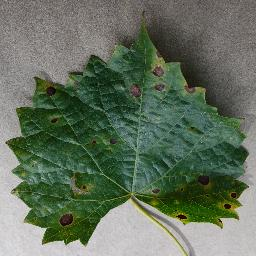

Image Name: 003d09ef-e16c-4e8a-badf-847d46cb3dc0___FAM_B.Rot 3184.JPG
Image Size: (256, 256)

DISEASE PREDICTION RESULT

Predicted Disease:
Grape Black Rot

Prediction Confidence: 51.98%

Top 5 Predictions:
--------------------------------------------------
1. Grape Black Rot --> 51.98%
2. Grape Esca --> 18.60%
3. Grape Leaf Blight --> 9.92%
4. Tomato Early Blight --> 2.38%
5. Tomato Bacterial Spot --> 2.27%

⚠ LOW CONFIDENCE: 51.98%
Please verify the image or consult an agricultural expert.


In [ ]:
# ============================================================
# CELL 20 - UPLOAD IMAGE + DISEASE PREDICTION
# ============================================================

from google.colab import files
from PIL import Image
import io
import numpy as np
import torch
from IPython.display import display

# 1. Upload image
uploaded = files.upload()

if not uploaded:
    raise RuntimeError("No image was uploaded.")

uploaded_name = next(iter(uploaded))
image_bytes = uploaded[uploaded_name]

image = Image.open(
    io.BytesIO(image_bytes)
).convert("RGB")

# 2. Display uploaded image FIRST
print("\n" + "=" * 70)
print("UPLOADED CROP IMAGE")
print("=" * 70)

display(image)

print("Image Name:", uploaded_name)
print("Image Size:", image.size)

# 3. Create SigLIP embedding
inputs = siglip_processor(
    images=image,
    return_tensors="pt"
)

inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

with torch.no_grad():
    features = get_siglip_image_embedding(inputs)

features_np = features.cpu().numpy()

# 4. Predict probabilities
probabilities = classifier.predict_proba(
    features_np
)[0]

sorted_indices = np.argsort(
    probabilities
)[::-1]

# 5. Top prediction
top_index = sorted_indices[0]

predicted_class_index = int(
    classifier.classes_[top_index]
)

predicted_disease = DISEASE_LABELS[
    predicted_class_index
]

prediction_confidence = float(
    probabilities[top_index]
)

# 6. Display result AFTER image
print("\n" + "=" * 70)
print("DISEASE PREDICTION RESULT")
print("=" * 70)

print("\nPredicted Disease:")
print(predicted_disease)

print(
    "\nPrediction Confidence:",
    f"{prediction_confidence * 100:.2f}%"
)

# 7. Top 5 predictions
print("\nTop 5 Predictions:")
print("-" * 50)

for rank, index in enumerate(
    sorted_indices[:5],
    start=1
):
    class_index = int(
        classifier.classes_[index]
    )

    label = DISEASE_LABELS[
        class_index
    ]

    confidence = probabilities[index] * 100

    print(
        f"{rank}. {label} --> {confidence:.2f}%"
    )

# 8. Confidence status
print("\n" + "=" * 70)

if prediction_confidence >= 0.85:
    print(
        f"✓ HIGH CONFIDENCE PREDICTION: "
        f"{prediction_confidence * 100:.2f}%"
    )
else:
    print(
        f"⚠ LOW CONFIDENCE: "
        f"{prediction_confidence * 100:.2f}%"
    )

    print(
        "Please verify the image or consult an agricultural expert."
    )

print("=" * 70)

# 9. Save prediction for next cell
uploaded_image = image
predicted_disease_result = predicted_disease
predicted_confidence_result = prediction_confidence

In [ ]:
# ============================================================
# CELL 21 — COMPLETE 7-DAY TAMIL ACTION PLAN + AUDIO
# FIXED VERSION
# ============================================================

from gtts import gTTS
from IPython.display import Audio, display
from pathlib import Path
import re


print("=" * 70)
print("CELL 21 - COMPLETE 7-DAY TAMIL ACTION PLAN")
print("=" * 70)


# ------------------------------------------------------------
# 1. Get predicted disease
# ------------------------------------------------------------

if "predicted_disease_result" not in globals():
    raise RuntimeError(
        "Please run Cell 20 first."
    )

disease = predicted_disease_result

print("\nDetected Disease:")
print(disease)


# ------------------------------------------------------------
# 2. Check knowledge base
# ------------------------------------------------------------

if "knowledge_base" not in globals():
    raise RuntimeError(
        "knowledge_base is not available. "
        "Please run Cell 10 first."
    )

if disease not in knowledge_base:
    raise KeyError(
        f"{disease} is not available in knowledge_base."
    )


# ------------------------------------------------------------
# 3. Create English 7-day plan
# ------------------------------------------------------------

seven_day_plan = create_7_day_plan(
    disease=disease,
    knowledge=knowledge_base
)


# ------------------------------------------------------------
# 4. Clean English text
# ------------------------------------------------------------

def clean_plan_text(text):

    text = str(text)

    # Remove markdown/special symbols
    text = re.sub(
        r"[#*_`~]+",
        "",
        text
    )

    # Remove extra spaces
    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text.strip()


cleaned_plan = {}

for day, action in seven_day_plan.items():

    cleaned_plan[day] = clean_plan_text(action)


# ------------------------------------------------------------
# 5. Translate ONE DAY at a time
# ------------------------------------------------------------

def translate_plan_day(text):

    if not text or not text.strip():
        return ""

    translation_tokenizer.src_lang = "eng_Latn"

    inputs = translation_tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=256
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    tamil_token_id = (
        translation_tokenizer
        .convert_tokens_to_ids("tam_Taml")
    )

    with torch.no_grad():

        output = translation_model.generate(
            **inputs,
            forced_bos_token_id=tamil_token_id,
            max_new_tokens=120,
            num_beams=4,
            do_sample=False,
            no_repeat_ngram_size=3,
            repetition_penalty=1.2,
            early_stopping=True
        )

    translated = (
        translation_tokenizer
        .batch_decode(
            output,
            skip_special_tokens=True
        )[0]
    )

    return translated.strip()


# ------------------------------------------------------------
# 6. Remove repeated Tamil sentences
# ------------------------------------------------------------

def remove_repeated_sentences(text):

    if not text:
        return ""

    # Split approximately on Tamil/English sentence endings
    sentences = re.split(
        r"(?<=[.!?।])\s+",
        text
    )

    unique_sentences = []
    seen = set()

    for sentence in sentences:

        sentence = sentence.strip()

        if not sentence:
            continue

        normalized = re.sub(
            r"\s+",
            " ",
            sentence
        ).strip()

        key = normalized.lower()

        if key not in seen:
            seen.add(key)
            unique_sentences.append(
                normalized
            )

    return " ".join(unique_sentences)


# ------------------------------------------------------------
# 7. Translate every day separately
# ------------------------------------------------------------

tamil_plan = {}

for day, english_action in cleaned_plan.items():

    tamil_action = translate_plan_day(
        english_action
    )

    tamil_action = remove_repeated_sentences(
        tamil_action
    )

    if not tamil_action:
        tamil_action = (
            "இந்த நாளுக்கான அறிவுரை கிடைக்கவில்லை."
        )

    tamil_plan[day] = tamil_action


# ------------------------------------------------------------
# 8. Display clean Tamil plan
# ------------------------------------------------------------

print("\n")
print("🇮🇳 COMPLETE TAMIL ACTION PLAN")
print("=" * 70)

tamil_day_names = {
    "Day 1": "நாள் 1",
    "Day 2": "நாள் 2",
    "Day 3": "நாள் 3",
    "Day 4": "நாள் 4",
    "Day 5": "நாள் 5",
    "Day 6": "நாள் 6",
    "Day 7": "நாள் 7"
}


for day, tamil_action in tamil_plan.items():

    tamil_day = tamil_day_names.get(
        day,
        day
    )

    print(f"\n{tamil_day}")
    print("-" * 50)
    print(tamil_action)


# ------------------------------------------------------------
# 9. Create clean Tamil audio text
# ------------------------------------------------------------

tamil_audio_parts = []

tamil_audio_parts.append(
    f"கண்டறியப்பட்ட தாவர நோய் {disease}."
)

tamil_audio_parts.append(
    "ஏழு நாட்களுக்கான செயல் திட்டம்."
)


for day, tamil_action in tamil_plan.items():

    tamil_day = tamil_day_names.get(
        day,
        day
    )

    tamil_audio_parts.append(
        f"{tamil_day}. {tamil_action}."
    )


tamil_audio_text = " ".join(
    tamil_audio_parts
)


# ------------------------------------------------------------
# 10. Final audio text cleanup
# ------------------------------------------------------------

tamil_audio_text = re.sub(
    r"[#*_`~\[\]{}<>|]+",
    "",
    tamil_audio_text
)

tamil_audio_text = re.sub(
    r"\s+",
    " ",
    tamil_audio_text
).strip()


# ------------------------------------------------------------
# 11. Save Tamil audio
# ------------------------------------------------------------

audio_dir = Path(
    "/content/AgricultureAssistant/audio"
)

audio_dir.mkdir(
    parents=True,
    exist_ok=True
)

audio_path = (
    audio_dir /
    "final_tamil_7_day_action_plan.mp3"
)


tts = gTTS(
    text=tamil_audio_text,
    lang="ta",
    slow=False
)

tts.save(
    str(audio_path)
)


# ------------------------------------------------------------
# 12. Final output
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("✅ COMPLETE 7-DAY TAMIL AUDIO CREATED")
print("=" * 70)

print("\nAudio file:")
print(audio_path)

display(
    Audio(
        str(audio_path),
        autoplay=False
    )
)

print("\n✅ CELL 21 COMPLETED SUCCESSFULLY")

[transformers] Both `max_new_tokens` (=120) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


CELL 21 - COMPLETE 7-DAY TAMIL ACTION PLAN

Detected Disease:
Tomato Early Blight


[transformers] Both `max_new_tokens` (=120) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=120) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=120) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=120) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface



🇮🇳 COMPLETE TAMIL ACTION PLAN

நாள் 1
--------------------------------------------------
தக்காளி ஆரம்ப வெடிப்பு அறிகுறிகளுக்காக பயிரை கவனமாக ஆய்வு செய்யவும். பொருத்தமானால் கடுமையாக பாதிக்கப்பட்ட தாவரப் பொருளை அகற்றவும்.

நாள் 2
--------------------------------------------------
பாதிக்கப்பட்ட தாவரங்களை தொடர்ந்து கண்காணிக்கவும். இந்த சிகிச்சை வழிகாட்டுதல்களை பின்பற்றவும்ஃ பாதிக்கப்பட்ட இலைகளை அகற்றி, பொருத்தமானால் பரிந்துரைக்கப்பட்ட பூஞ்சை மருந்து பயன்படுத்தவும்.

நாள் 3
--------------------------------------------------
அருகிலுள்ள தாவரங்களில் இதேபோன்ற அறிகுறிகளைக் கண்டறியவும், நல்ல கள சுகாதாரத்தை பராமரிக்கவும்.

நாள் 4
--------------------------------------------------
நோயின் முன்னேற்றத்தை கண்காணிக்கவும், இலை ஈரப்பதத்தை அதிகரிக்கும் நிலைகளை தவிர்க்கவும்.

நாள் 5
--------------------------------------------------
நோய்களைக் கட்டுப்படுத்த பரிந்துரைக்கப்பட்ட நடைமுறையைத் தொடரவும். தடுப்பு வழிகாட்டுதல்ஃ கள சுகாதாரத்தை பராமரிக்கவும், பயிர் சுழற்சியைப் பயன்படுத்தவும்.

நாள் 6
----------------


✅ CELL 21 COMPLETED SUCCESSFULLY


In [ ]:
# ============================================================
# CELL 22 — TAMIL VOICE → AIR-RAG → QWEN → TAMIL AUDIO
# ============================================================

from google.colab import files
from IPython.display import Audio, display
from pathlib import Path

# ------------------------------------------------------------
# 1. Upload Tamil voice
# ------------------------------------------------------------

print("🎤 Upload your Tamil voice recording")

uploaded_audio = files.upload()

if not uploaded_audio:
    raise RuntimeError("No audio file was uploaded.")

audio_filename = next(iter(uploaded_audio.keys()))

print("\n✅ Audio uploaded:", audio_filename)

# ------------------------------------------------------------
# 2. Tamil Speech → Text
# ------------------------------------------------------------

tamil_question = transcribe_tamil_audio(audio_filename)

print("\n🎤 FARMER'S TAMIL QUESTION")
print("=" * 60)
print(tamil_question)

if not tamil_question.strip():
    raise RuntimeError("Could not recognize the Tamil audio.")

# ------------------------------------------------------------
# 3. Tamil → English
# ------------------------------------------------------------

english_question = translate_to_english(tamil_question)

print("\n🌐 ENGLISH TRANSLATION")
print("=" * 60)
print(english_question)

# ------------------------------------------------------------
# 4. AIR-RAG Retrieval
# ------------------------------------------------------------

retrieved_docs = air_rag_retrieve(
    disease=predicted_disease_result,
    farmer_question=english_question,
    top_k=3
)

print("\n📚 AIR-RAG RETRIEVED KNOWLEDGE")
print("=" * 60)

for i, doc in enumerate(retrieved_docs, 1):
    print(f"\nDocument {i}:")
    print(doc)

# ------------------------------------------------------------
# 5. Qwen Response
# ------------------------------------------------------------

# IMPORTANT:
# Use the existing function from Cell 13.
# Do NOT pass the unsupported keyword "retrieved_documents".

ai_response = generate_agricultural_response(
    predicted_disease_result,
    english_question,
    retrieved_docs
)

print("\n🤖 AI AGRICULTURAL RESPONSE")
print("=" * 60)
print(ai_response)

# ------------------------------------------------------------
# 6. English → Tamil
# ------------------------------------------------------------

final_tamil_response = translate_to_tamil(ai_response)

print("\n🇮🇳 FINAL TAMIL RESPONSE")
print("=" * 60)
print(final_tamil_response)

# ------------------------------------------------------------
# 7. Tamil → Speech
# ------------------------------------------------------------

audio_dir = Path("/content/AgricultureAssistant/audio")
audio_dir.mkdir(parents=True, exist_ok=True)

voice_output_path = audio_dir / "farmer_tamil_ai_response.mp3"

tts = gTTS(
    text=final_tamil_response,
    lang="ta",
    slow=False
)

tts.save(str(voice_output_path))

print("\n" + "=" * 60)
print("🔊 FINAL TAMIL AI AUDIO CREATED")
print("📁", voice_output_path)

display(
    Audio(
        str(voice_output_path),
        autoplay=False
    )
)

🎤 Upload your Tamil voice recording


Saving 1790576985264393661tzihg98c-voicemaker.in-speech.mp3 to 1790576985264393661tzihg98c-voicemaker.in-speech (1).mp3

✅ Audio uploaded: 1790576985264393661tzihg98c-voicemaker.in-speech (1).mp3


[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



🎤 FARMER'S TAMIL QUESTION
என் செடியை என்ன நோய் பாதிக்கிறது?

🌐 ENGLISH TRANSLATION
What is the disease affecting my plant?

📚 AIR-RAG RETRIEVED KNOWLEDGE

Document 1:
query

Document 2:
documents

Document 3:
metadatas

Document 4:
distances

Document 5:
confidence

Document 6:
accepted

Document 7:
retrieval_log


[transformers] Both `max_new_tokens` (=512) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



🤖 AI AGRICULTURAL RESPONSE
Disease:

Tomato Early Blights

What it Means:

It refers to the fungal disease caused primarily by the fungus Alternaria alternata, which affects tomato plants during their early stages of growth.

What You Can Do:

- Remove affected leaves immediately for better air circulation.
- Apply a fungicidal spray as soon as possible after infection.
- Consider rotating crops to prevent further spread in fields prone to blights.

Preventive Measures:

- Maintain good soil health through proper fertilization and irrigation practices.
- Avoid overwatering and ensure adequate drainage.
- Regularly inspect your tomato plants for signs of blights before planting new rows.

Caution:

- Keep all tools clean and sanitized between uses.
- Wear protective clothing when handling infected material.

Remember:

- The symptoms typically appear within 2 weeks of infection but may take longer depending on environmental conditions.
- Treatment options include physical removal of di

In [ ]:
# CELL 21 — OPTION 1
# IMPROVED TAMIL TTS: SHORT SENTENCES + CLEAN TEXT + NATURAL PAUSES

import os
import re
from gtts import gTTS
from IPython.display import Audio, display

print("🇮🇳 TAMIL ACTION PLAN + IMPROVED VOICE")
print("=" * 60)

# ---------------------------------------------------------
# 1. GET DETECTED DISEASE
# ---------------------------------------------------------

if "disease" not in globals():
    raise NameError("Disease prediction is not available. Run Cell 20 first.")

if disease not in knowledge_base:
    raise KeyError(f"{disease} not found in knowledge_base.")

# ---------------------------------------------------------
# 2. CREATE 7-DAY PLAN
# ---------------------------------------------------------

seven_day_plan = create_7_day_plan(
    disease=disease,
    knowledge=knowledge_base
)

print(f"\nDetected Disease: {disease}\n")

# ---------------------------------------------------------
# 3. CLEAN ENGLISH TEXT BEFORE TRANSLATION
# ---------------------------------------------------------

def clean_plan_text(text):
    text = str(text)

    # Remove markdown/special characters
    text = re.sub(r'[#*_`~]+', '', text)
    text = re.sub(r'[\[\]{}<>|]+', '', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text)

    return text.strip()


# ---------------------------------------------------------
# 4. TRANSLATE ONE DAY AT A TIME
# ---------------------------------------------------------

def translate_one_day(text):

    text = clean_plan_text(text)

    if not text:
        return ""

    translation_tokenizer.src_lang = "eng_Latn"

    inputs = translation_tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=256
    )

    inputs = {
        k: v.to(device)
        for k, v in inputs.items()
    }

    forced_bos_token_id = translation_tokenizer.convert_tokens_to_ids(
        "tam_Taml"
    )

    with torch.no_grad():

        output = translation_model.generate(
            **inputs,
            forced_bos_token_id=forced_bos_token_id,
            max_new_tokens=120,
            num_beams=4,
            do_sample=False,
            repetition_penalty=1.2,
            no_repeat_ngram_size=3,
            early_stopping=True
        )

    tamil = translation_tokenizer.batch_decode(
        output,
        skip_special_tokens=True
    )[0]

    tamil = tamil.strip()

    # Remove unwanted symbols
    tamil = re.sub(r'[#*_`~]+', '', tamil)
    tamil = re.sub(r'[\[\]{}<>|]+', '', tamil)

    # Remove excessive spaces
    tamil = re.sub(r'\s+', ' ', tamil)

    return tamil.strip()


# ---------------------------------------------------------
# 5. REMOVE REPEATED SENTENCES
# ---------------------------------------------------------

def remove_repeated_sentences(text):

    text = text.strip()

    # Split approximately by Tamil/English sentence endings
    sentences = re.split(r'(?<=[.!?।])\s+', text)

    cleaned = []
    seen = set()

    for sentence in sentences:

        sentence = sentence.strip()

        if not sentence:
            continue

        key = re.sub(r'\s+', ' ', sentence).lower()

        if key not in seen:
            cleaned.append(sentence)
            seen.add(key)

    return " ".join(cleaned)


# ---------------------------------------------------------
# 6. TAMIL DAY NAMES
# ---------------------------------------------------------

tamil_days = {
    "Day 1": "நாள் ஒன்று",
    "Day 2": "நாள் இரண்டு",
    "Day 3": "நாள் மூன்று",
    "Day 4": "நாள் நான்கு",
    "Day 5": "நாள் ஐந்து",
    "Day 6": "நாள் ஆறு",
    "Day 7": "நாள் ஏழு"
}


# ---------------------------------------------------------
# 7. TRANSLATE EACH DAY SEPARATELY
# ---------------------------------------------------------

tamil_plan = {}

for day, action in seven_day_plan.items():

    english_action = clean_plan_text(action)

    tamil_action = translate_one_day(english_action)

    tamil_action = remove_repeated_sentences(tamil_action)

    tamil_plan[day] = tamil_action


# ---------------------------------------------------------
# 8. DISPLAY TAMIL PLAN
# ---------------------------------------------------------

print("\n🇮🇳 COMPLETE TAMIL ACTION PLAN")
print("=" * 60)

print(f"\nநோய்: {disease}\n")

for day in tamil_days:

    print(f"{tamil_days[day]}")
    print(tamil_plan[day])
    print()


# ---------------------------------------------------------
# 9. CREATE SHORT, NATURAL TTS TEXT
# ---------------------------------------------------------

tts_parts = []

# Introduction
tts_parts.append(
    f"கண்டறியப்பட்ட நோய் {disease}."
)

tts_parts.append(
    "ஏழு நாள் செயல் திட்டம் தொடங்குகிறது."
)

# Add each day separately
for day in tamil_days:

    day_name = tamil_days[day]
    action = tamil_plan[day]

    if action:

        tts_parts.append(
            f"{day_name}. {action}."
        )

# Ending
tts_parts.append(
    "தாவரத்தை தினமும் கவனமாக கண்காணிக்கவும்."
)

final_tamil_audio_text = " ".join(tts_parts)

# Final cleaning
final_tamil_audio_text = re.sub(
    r'[#*_`~\[\]{}<>|]+',
    '',
    final_tamil_audio_text
)

final_tamil_audio_text = re.sub(
    r'\s+',
    ' ',
    final_tamil_audio_text
).strip()


# ---------------------------------------------------------
# 10. SAVE TAMIL AUDIO
# ---------------------------------------------------------

output_path = "/content/AgricultureAssistant/tamil_action_plan_option1.mp3"

os.makedirs(
    os.path.dirname(output_path),
    exist_ok=True
)

tts = gTTS(
    text=final_tamil_audio_text,
    lang="ta",
    slow=False
)

tts.save(output_path)


# ---------------------------------------------------------
# 11. SHOW RESULT
# ---------------------------------------------------------

print("\n" + "=" * 60)
print("🔊 AUDIO READY")
print("=" * 60)

print(f"\nAudio saved at:")
print(output_path)

display(Audio(output_path, autoplay=False))

[transformers] Both `max_new_tokens` (=120) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


🇮🇳 TAMIL ACTION PLAN + IMPROVED VOICE

Detected Disease: Tomato Early Blight



[transformers] Both `max_new_tokens` (=120) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=120) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=120) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=120) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface


🇮🇳 COMPLETE TAMIL ACTION PLAN

நோய்: Tomato Early Blight

நாள் ஒன்று
தக்காளி ஆரம்ப வெடிப்பு அறிகுறிகளுக்காக பயிரை கவனமாக ஆய்வு செய்யவும். பொருத்தமானால் கடுமையாக பாதிக்கப்பட்ட தாவரப் பொருளை அகற்றவும்.

நாள் இரண்டு
பாதிக்கப்பட்ட தாவரங்களை தொடர்ந்து கண்காணிக்கவும். இந்த சிகிச்சை வழிகாட்டுதல்களை பின்பற்றவும்ஃ பாதிக்கப்பட்ட இலைகளை அகற்றி, பொருத்தமானால் பரிந்துரைக்கப்பட்ட பூஞ்சை மருந்து பயன்படுத்தவும்.

நாள் மூன்று
அருகிலுள்ள தாவரங்களில் இதேபோன்ற அறிகுறிகளைக் கண்டறியவும், நல்ல கள சுகாதாரத்தை பராமரிக்கவும்.

நாள் நான்கு
நோயின் முன்னேற்றத்தை கண்காணிக்கவும், இலை ஈரப்பதத்தை அதிகரிக்கும் நிலைகளை தவிர்க்கவும்.

நாள் ஐந்து
நோய்களைக் கட்டுப்படுத்த பரிந்துரைக்கப்பட்ட நடைமுறையைத் தொடரவும். தடுப்பு வழிகாட்டுதல்ஃ கள சுகாதாரத்தை பராமரிக்கவும், பயிர் சுழற்சியைப் பயன்படுத்தவும்.

நாள் ஆறு
பயிரை மறுபரிசீலனை செய்து, தேவைப்பட்டால், புதிதாக கண்டறியப்பட்ட கடுமையாக பாதிக்கப்பட்ட தாவரப் பொருளை அகற்றவும்.

நாள் ஏழு
பயிர் நிலையை முதல் நாளுடன் ஒப்பிடுங்கள் மற்றும் வழக்கமான கண்காணிப்பு மற்றும் பரிந்துரைக்கப்பட்ட விவ